# Figure S19 — Host-interaction sensitivity

This notebook plots the measured melt-inclusion glasses and the compositions obtained by subtracting or adding 5% of the measured host composition. These vectors are compositional sensitivity tests, not modeled fractional-crystallization paths.

## 1. Imports and shared Science Advances setup

This section reproduces the publication settings from `00_Setup/Plotting_Setup.ipynb`. There are no custom functions.

In [1]:
from pathlib import Path
import hashlib

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from PIL import Image

SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8
BASE_TEXT_SIZE_PT = 8.0
PANEL_LABEL_SIZE_PT = 9.0
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300
PUBLICATION_FONT = 'Arial'

installed_font_names = {entry.name for entry in font_manager.fontManager.ttflist}
if PUBLICATION_FONT not in installed_font_names:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': [PUBLICATION_FONT],
    'font.size': BASE_TEXT_SIZE_PT,
    'axes.labelsize': BASE_TEXT_SIZE_PT,
    'axes.titlesize': BASE_TEXT_SIZE_PT,
    'xtick.labelsize': BASE_TEXT_SIZE_PT,
    'ytick.labelsize': BASE_TEXT_SIZE_PT,
    'legend.fontsize': BASE_TEXT_SIZE_PT,
    'legend.title_fontsize': BASE_TEXT_SIZE_PT,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.grid': False,
    'axes.spines.top': True,
    'axes.spines.right': True,
    'axes.linewidth': 0.5,
    'lines.linewidth': 0.75,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.minor.visible': False,
    'ytick.minor.visible': False,
    'savefig.dpi': EXPORT_DPI,
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
})

print('Shared setup complete: Arial, 8-point text, 9-point bold panel labels, and 300 dpi export.')

Shared setup complete: Arial, 8-point text, 9-point bold panel labels, and 300 dpi export.


## 2. Figure S19 paths and plotting choices

Everything below is specific to Figure S19. The figure reads only the public S1 workbook.

In [2]:
PROJECT_ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / 'SA_MI_Draft_FinalFigures_Work/DataSheets').is_dir():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from inside the Glacier Peak Efforts project.')

WORK_ROOT = PROJECT_ROOT / 'SA_MI_Draft_FinalFigures_Work'
CURRENT_DIRECTORY = WORK_ROOT / 'Nov6_AllFigures' / 'Figure_S19_PEC'
OUTPUT_DIRECTORY = CURRENT_DIRECTORY / 'Figure_S19_PEC_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

SOURCE_PATH = WORK_ROOT / 'DataSheets' / 'Updated_Oct20' / 'Dechert_S1_AllData.xlsx'
SOURCE_SHEET = 'MI_Hosts_Plag_Pxy'
SOURCE_HASH_BEFORE = hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest()

SAMPLE_ORDER = ['74D', '74A', '75', '76A']
SAMPLE_COLORS = {'74D': '#F4A261', '74A': '#D55E00', '75': '#56B4E9', '76A': '#0072B2'}
SAMPLE_LABELS = {'74D': 'B Middle', '74A': 'B Base', '75': 'G Top', '76A': 'G Middle'}
PHASE_MARKERS = {'plag': 'o', 'pxy': 's'}
PEC_MINUS_COLOR = '#A1008F'
PEC_PLUS_COLOR = '#888888'

print(f'Source: {SOURCE_PATH.name} / {SOURCE_SHEET}')
print(f'Output directory: {OUTPUT_DIRECTORY}')

Source: Dechert_S1_AllData.xlsx / MI_Hosts_Plag_Pxy
Output directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S19_PEC/Figure_S19_PEC_Final


## 3. Read and prepare the Figure S19 data

Matrix glass is retained only as compositional context. Sensitivity vectors require finite measured-glass and measured-host values for all ten major oxides.

In [3]:
source_data = pd.read_excel(SOURCE_PATH, sheet_name=SOURCE_SHEET)
figure_data = source_data.copy()

OXIDE_NAMES = ['SiO2', 'TiO2', 'Al2O3', 'FeOt', 'MnO', 'MgO', 'CaO', 'Na2O', 'K2O', 'P2O5']
GLASS_COLUMNS = {oxide: f'{oxide}_SEMGlass' for oxide in OXIDE_NAMES}
HOST_COLUMNS = {oxide: f'{oxide}_host' for oxide in OXIDE_NAMES}
GLASS_SOURCE_COLUMNS = {
    'SiO2': 'SiO2_SEMGlass_AnhydoNorm',
    'TiO2': 'TiO2_SEMGlass_AnhydoNorm',
    'Al2O3': 'Al2O3_SEMGlass_AnhydoNorm',
    'FeOt': 'FeOtt_SEMGlass_AnhydoNorm',
    'MnO': 'MnO_SEMGlass_AnhydoNorm',
    'MgO': 'MgO_SEMGlass_AnhydoNorm',
    'CaO': 'CaO_SEMGlass_AnhydoNorm',
    'Na2O': 'Na2O_SEMGlass_AnhydoNorm',
    'K2O': 'K2O_SEMGlass_AnhydoNorm',
    'P2O5': 'P2O5_SEMGlass_AnhydoNorm',
}

required_columns = ['base_name', 'mineral_phase', *GLASS_SOURCE_COLUMNS.values(), *HOST_COLUMNS.values()]
missing_columns = [column for column in required_columns if column not in figure_data.columns]
if missing_columns:
    raise KeyError(f'Missing required S1 columns: {missing_columns}')

glass_values = {}
for oxide in OXIDE_NAMES:
    glass_values[GLASS_COLUMNS[oxide]] = pd.to_numeric(
        figure_data[GLASS_SOURCE_COLUMNS[oxide]], errors='coerce'
    )
figure_data = pd.concat([figure_data, pd.DataFrame(glass_values, index=figure_data.index)], axis=1)
for column in HOST_COLUMNS.values():
    figure_data[column] = pd.to_numeric(figure_data[column], errors='coerce')

figure_data['mineral_phase'] = figure_data['mineral_phase'].replace({'opx': 'pxy'})
figure_data['sample_key'] = pd.NA
for sample_key in SAMPLE_ORDER:
    sample_mask = figure_data['base_name'].astype('string').str.startswith(sample_key, na=False)
    figure_data.loc[sample_mask, 'sample_key'] = sample_key

matrix_mask = figure_data['base_name'].astype('string').str.contains('MTX', na=False)
complete_pair_mask = ~matrix_mask
for oxide in OXIDE_NAMES:
    complete_pair_mask &= figure_data[GLASS_COLUMNS[oxide]].notna()
    complete_pair_mask &= figure_data[HOST_COLUMNS[oxide]].notna()

pec_data = figure_data.loc[complete_pair_mask].copy()
matrix_data = figure_data.loc[matrix_mask].copy()

print(f'Source rows: {len(source_data)}')
print(f'Matrix-glass context rows: {len(matrix_data)}')
print(f'Rows with all ten glass-host oxide pairs: {len(pec_data)}')
print(pec_data.groupby(['sample_key', 'mineral_phase']).size())

Source rows: 212
Matrix-glass context rows: 13
Rows with all ten glass-host oxide pairs: 117
sample_key  mineral_phase
74A         plag             15
            pxy              23
74D         plag              8
            pxy              14
75          plag             11
            pxy              14
76A         plag             15
            pxy              17
dtype: int64


## 4. Plot and export Figure S19

For each oxide, the sensitivity composition is `host fraction × host + (1 − host fraction) × measured glass`, evaluated at −5%, 0%, and +5% host.

Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S19_PEC/Figure_S19_PEC_Final/Figure_S19_Targeted_PEC_Diagnostics.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S19_PEC/Figure_S19_PEC_Final/Figure_S19_Targeted_PEC_Diagnostics.png
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S19_PEC/Figure_S19_PEC_Final/Figure_S19_Targeted_PEC_Diagnostics.svg


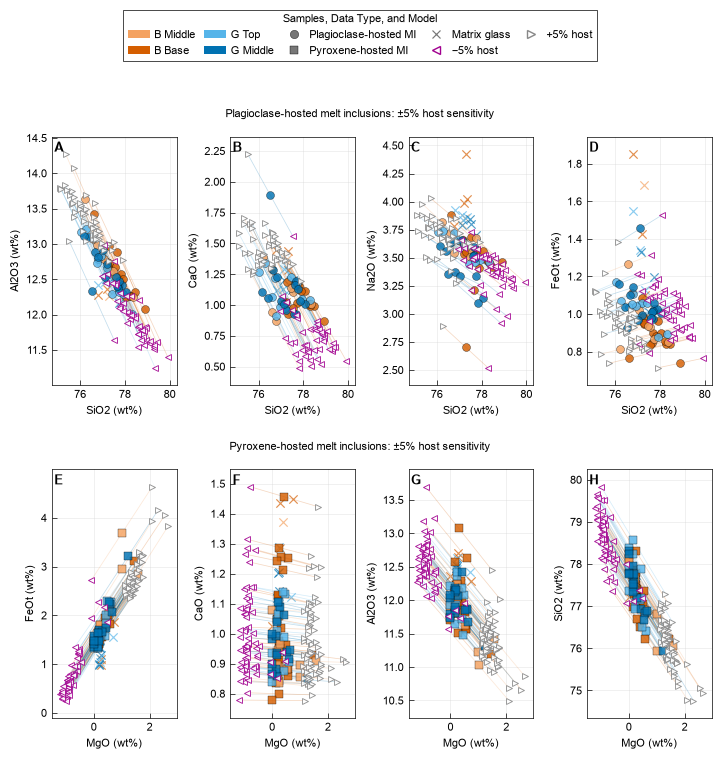

In [4]:
PANEL_SPECS = [
    ('A', 0, 0, 'plag', 'SiO2', 'Al2O3'),
    ('B', 0, 1, 'plag', 'SiO2', 'CaO'),
    ('C', 0, 2, 'plag', 'SiO2', 'Na2O'),
    ('D', 0, 3, 'plag', 'SiO2', 'FeOt'),
    ('E', 1, 0, 'pxy', 'MgO', 'FeOt'),
    ('F', 1, 1, 'pxy', 'MgO', 'CaO'),
    ('G', 1, 2, 'pxy', 'MgO', 'Al2O3'),
    ('H', 1, 3, 'pxy', 'MgO', 'SiO2'),
]

figure, axes = plt.subplots(2, 4, figsize=(DOUBLE_COLUMN_WIDTH_IN, MAXIMUM_RECOMMENDED_HEIGHT_IN))

for panel_label, row_index, column_index, phase, x_oxide, y_oxide in PANEL_SPECS:
    axis = axes[row_index, column_index]
    phase_data = pec_data.loc[pec_data['mineral_phase'].eq(phase)]

    for sample_key in SAMPLE_ORDER:
        matrix_sample = matrix_data.loc[
            matrix_data['sample_key'].eq(sample_key)
            & matrix_data[GLASS_COLUMNS[x_oxide]].notna()
            & matrix_data[GLASS_COLUMNS[y_oxide]].notna()
        ]
        axis.scatter(
            matrix_sample[GLASS_COLUMNS[x_oxide]], matrix_sample[GLASS_COLUMNS[y_oxide]],
            marker='x', s=36, color=SAMPLE_COLORS[sample_key],
            linewidths=0.85, alpha=0.68, zorder=1,
        )

    for _, record in phase_data.iterrows():
        sample_key = record['sample_key']
        color = SAMPLE_COLORS[sample_key]
        x_glass = record[GLASS_COLUMNS[x_oxide]]
        y_glass = record[GLASS_COLUMNS[y_oxide]]
        x_host = record[HOST_COLUMNS[x_oxide]]
        y_host = record[HOST_COLUMNS[y_oxide]]

        x_minus = -0.05 * x_host + 1.05 * x_glass
        y_minus = -0.05 * y_host + 1.05 * y_glass
        x_plus = 0.05 * x_host + 0.95 * x_glass
        y_plus = 0.05 * y_host + 0.95 * y_glass

        axis.plot([x_minus, x_glass, x_plus], [y_minus, y_glass, y_plus],
                  color=color, alpha=0.24, linewidth=0.55, zorder=2)
        axis.scatter(
            x_glass, y_glass, marker=PHASE_MARKERS[phase], s=(6.0 - MINIMUM_LINE_WIDTH_PT) ** 2,
            facecolor=color, edgecolor='black', linewidth=MINIMUM_LINE_WIDTH_PT,
            alpha=0.82, zorder=3,
        )
        axis.scatter(x_minus, y_minus, marker='<', s=18, facecolor='white',
                     edgecolor=PEC_MINUS_COLOR, linewidth=0.65, alpha=0.90, zorder=4)
        axis.scatter(x_plus, y_plus, marker='>', s=18, facecolor='white',
                     edgecolor=PEC_PLUS_COLOR, linewidth=0.65, alpha=0.90, zorder=4)

    axis.text(0.02, 0.98, panel_label, transform=axis.transAxes, ha='left', va='top',
              fontsize=PANEL_LABEL_SIZE_PT, fontweight='bold', zorder=10)
    axis.set_xlabel(f'{x_oxide} (wt%)')
    axis.set_ylabel(f'{y_oxide} (wt%)')
    axis.grid(True, color='#D9D9D9', linewidth=0.4, alpha=0.70)
    axis.margins(x=0.08, y=0.08)
    for spine in axis.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.5)

sample_handles = [Patch(facecolor=SAMPLE_COLORS[key], edgecolor='none', label=SAMPLE_LABELS[key])
                  for key in SAMPLE_ORDER]
symbol_handles = [
    Line2D([], [], linestyle='none', marker='o', markerfacecolor='#777777', markeredgecolor='black',
           markeredgewidth=MINIMUM_LINE_WIDTH_PT, markersize=6, label='Plagioclase-hosted MI'),
    Line2D([], [], linestyle='none', marker='s', markerfacecolor='#777777', markeredgecolor='black',
           markeredgewidth=MINIMUM_LINE_WIDTH_PT, markersize=6, label='Pyroxene-hosted MI'),
    Line2D([], [], linestyle='none', marker='x', color='#777777', markeredgewidth=0.85,
           markersize=6, label='Matrix glass'),
    Line2D([], [], linestyle='none', marker='<', markerfacecolor='white', markeredgecolor=PEC_MINUS_COLOR,
           markersize=6, label='−5% host'),
    Line2D([], [], linestyle='none', marker='>', markerfacecolor='white', markeredgecolor=PEC_PLUS_COLOR,
           markersize=6, label='+5% host'),
]
legend = figure.legend(
    handles=sample_handles + symbol_handles, title='Samples, Data Type, and Model',
    loc='upper center', bbox_to_anchor=(0.5, 0.985), ncol=5,
    frameon=True, fancybox=False, facecolor='white', edgecolor='black', framealpha=1.0,
    borderpad=0.4, handletextpad=0.4, columnspacing=0.8, labelspacing=0.5,
)
legend.get_frame().set_linewidth(0.5)

figure.subplots_adjust(left=0.075, right=0.985, bottom=0.07, top=0.815, wspace=0.43, hspace=0.34)
row_title_offset = 0.025
top_row_title_y = max(axis.get_position().y1 for axis in axes[0, :]) + row_title_offset
bottom_row_title_y = max(axis.get_position().y1 for axis in axes[1, :]) + row_title_offset
figure.text(0.5, top_row_title_y, 'Plagioclase-hosted melt inclusions: ±5% host sensitivity', ha='center')
figure.text(0.5, bottom_row_title_y, 'Pyroxene-hosted melt inclusions: ±5% host sensitivity', ha='center')

PDF_PATH = OUTPUT_DIRECTORY / 'Figure_S19_Targeted_PEC_Diagnostics.pdf'
PNG_PATH = OUTPUT_DIRECTORY / 'Figure_S19_Targeted_PEC_Diagnostics.png'
SVG_PATH = OUTPUT_DIRECTORY / 'Figure_S19_Targeted_PEC_Diagnostics.svg'
figure.savefig(PDF_PATH, format='pdf', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(PNG_PATH, format='png', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(SVG_PATH, format='svg', dpi=EXPORT_DPI, facecolor='white', transparent=False)

print(f'Saved: {PDF_PATH}')
print(f'Saved: {PNG_PATH}')
print(f'Saved: {SVG_PATH}')
plt.show()

## 5. Short output check

In [5]:
if len(source_data) != 212 or len(matrix_data) != 13 or len(pec_data) != 117:
    raise ValueError('The established Figure S19 source population has changed.')
if len(pec_data.loc[pec_data['mineral_phase'].eq('plag')]) != 49:
    raise ValueError('The established plagioclase-hosted population has changed.')
if len(pec_data.loc[pec_data['mineral_phase'].eq('pxy')]) != 68:
    raise ValueError('The established pyroxene-hosted population has changed.')
if hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest() != SOURCE_HASH_BEFORE:
    raise RuntimeError('The source workbook changed during execution.')

with Image.open(PNG_PATH) as image:
    png_dimensions = image.size
if png_dimensions != (2175, 2340):
    raise ValueError(f'Unexpected PNG dimensions: {png_dimensions}')
if b'/Type3' in PDF_PATH.read_bytes():
    raise ValueError('The PDF contains Type 3 fonts.')
if '<text' not in SVG_PATH.read_text(encoding='utf-8'):
    raise ValueError('The SVG does not retain live text.')

print('Check passed: source populations and ±5% host calculations are unchanged.')
print(f'Final size: {DOUBLE_COLUMN_WIDTH_IN:.2f} x {MAXIMUM_RECOMMENDED_HEIGHT_IN:.2f} in; PNG: {png_dimensions[0]} x {png_dimensions[1]} px.')

Check passed: source populations and ±5% host calculations are unchanged.
Final size: 7.25 x 7.80 in; PNG: 2175 x 2340 px.
